In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/car data.csv')

# Display first 5 rows
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Column information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (301, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Statistical Summary:


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000



Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Duplicate Records: 2


In [4]:
# Check duplicate records
duplicate_rows = df[df.duplicated()]

print("Duplicate Records:")
display(duplicate_rows)

Duplicate Records:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


In [5]:
# Remove duplicate records
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

# Verify cleaned dataset
print("Updated Dataset Shape:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())
print("Missing Values:")
print(df.isnull().sum())

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


In [6]:
# Find the latest year in the dataset
latest_year = df['Year'].max()

# Create car age feature
df['Car_Age'] = latest_year - df['Year']

# Check new feature
display(df[['Year', 'Car_Age']].head())

print("Latest Year in Dataset:", latest_year)

,Year,Car_Age
0,2014,4
1,2013,5
2,2017,1
3,2011,7
4,2014,4


Latest Year in Dataset: 2018


In [7]:
# Numerical columns summary
numerical_cols = df.select_dtypes(include=np.number).columns

display(df[numerical_cols].describe().round(2))

,Year,Selling_Price,Present_Price,Driven_kms,Owner,Car_Age
count,301.00,301.00,301.00,301.00,301.00,301.00
mean,2013.63,4.66,7.63,36947.21,0.04,4.37
std,2.89,5.08,8.64,38886.88,0.25,2.89
min,2003.00,0.10,0.32,500.00,0.00,0.00
25%,2012.00,0.90,1.20,15000.00,0.00,2.00
50%,2014.00,3.60,6.40,32000.00,0.00,4.00
75%,2016.00,6.00,9.90,48767.00,0.00,6.00
max,2018.00,35.00,92.60,500000.00,3.00,15.00


In [8]:
# Categorical columns
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col} - Unique Values:")
    print(df[col].value_counts())


Car_Name - Unique Values:
Car_Name
city                  26
corolla altis         16
verna                 14
fortuner              11
brio                  10
                      ..
Honda Activa 125       1
Hero Hunk              1
Hero  Ignitor Disc     1
Hero  CBZ Xtreme       1
Bajaj  ct 100          1
Name: count, Length: 98, dtype: int64

Fuel_Type - Unique Values:
Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64

Selling_type - Unique Values:
Selling_type
Dealer        195
Individual    106
Name: count, dtype: int64

Transmission - Unique Values:
Transmission
Manual       261
Automatic     40
Name: count, dtype: int64


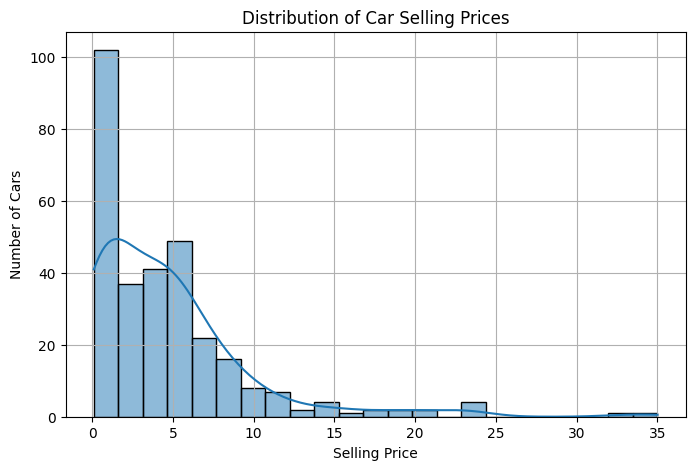

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Selling_Price'], kde=True)

plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')
plt.grid(True)
plt.show()

Correlation with Selling Price:


,Selling_Price
Selling_Price,1.00
Present_Price,0.88
Year,0.24
Driven_kms,0.03
Owner,-0.09
Car_Age,-0.24


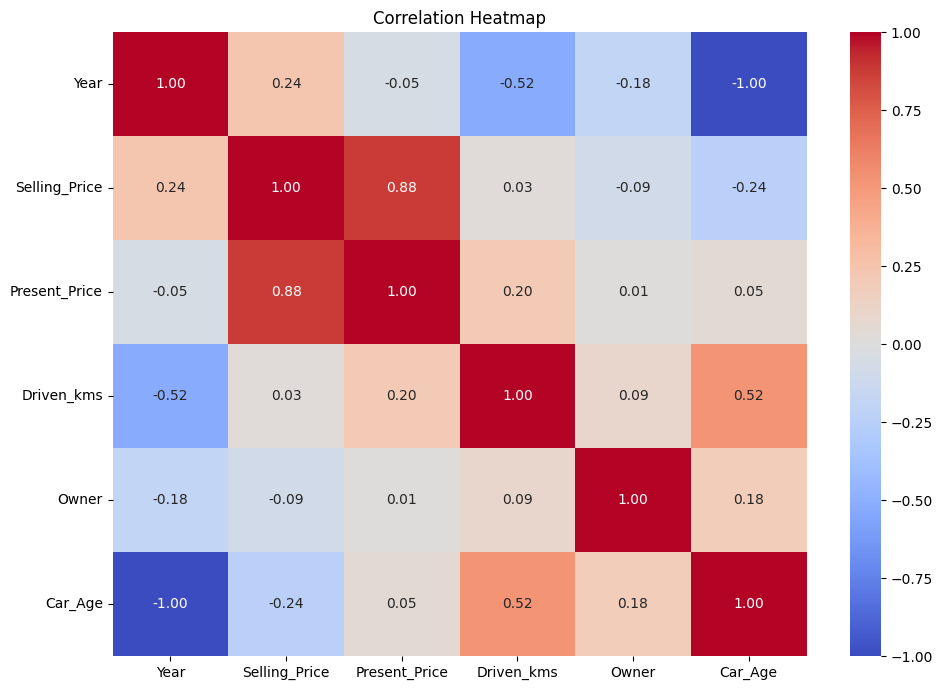

In [10]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation
correlation = numeric_df.corr()

# Display correlation with target
print("Correlation with Selling Price:")
display(
    correlation['Selling_Price']
    .sort_values(ascending=False)
    .round(2)
)

# Correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [11]:
# Create a copy for model preparation
model_df = df.copy()

# Drop Car_Name
model_df = model_df.drop(columns=['Car_Name'])

# Encode categorical columns
model_df = pd.get_dummies(
    model_df,
    columns=['Fuel_Type', 'Selling_type', 'Transmission'],
    drop_first=True,
    dtype=int
)

# Display encoded dataset
display(model_df.head())

print("Shape after encoding:", model_df.shape)
print("\nColumns:")
print(model_df.columns.tolist())

,Year,Selling_Price,Present_Price,Driven_kms,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual
0,2014,3.35,5.59,27000,0,4,0,1,0,1
1,2013,4.75,9.54,43000,0,5,1,0,0,1
2,2017,7.25,9.85,6900,0,1,0,1,0,1
3,2011,2.85,4.15,5200,0,7,0,1,0,1
4,2014,4.60,6.87,42450,0,4,1,0,0,1


Shape after encoding: (301, 10)

Columns:
['Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Owner', 'Car_Age', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Selling_type_Individual', 'Transmission_Manual']


In [12]:
# Separate features and target

X = model_df.drop('Selling_Price', axis=1)
y = model_df['Selling_Price']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Features Shape: (301, 9)
Target Shape: (301,)


,Year,Present_Price,Driven_kms,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual
0,2014,5.59,27000,0,4,0,1,0,1
1,2013,9.54,43000,0,5,1,0,0,1
2,2017,9.85,6900,0,1,0,1,0,1
3,2011,4.15,5200,0,7,0,1,0,1
4,2014,6.87,42450,0,4,1,0,0,1


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (240, 9)
Testing Features: (61, 9)
Training Target: (240,)
Testing Target: (61,)


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

# Train models
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    print(name, "training completed!")

Linear Regression training completed!
Decision Tree training completed!
Random Forest training completed!


In [15]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.216,3.481,1.866,0.849
1,Decision Tree,0.650,0.960,0.980,0.958
2,Random Forest,0.620,0.864,0.930,0.962


In [16]:
# Select the best model
best_model = trained_models['Random Forest']

# Make predictions
y_pred = best_model.predict(X_test)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison['Difference'] = (
    comparison['Actual Price'] -
    comparison['Predicted Price']
)

display(comparison.head(15).round(2))

,Actual Price,Predicted Price,Difference
0,0.35,0.45,-0.10
1,10.11,11.05,-0.94
2,4.95,4.92,0.03
3,0.15,0.22,-0.07
4,6.95,7.67,-0.72
5,7.45,6.29,1.16
6,1.10,1.10,-0.00
7,0.50,0.59,-0.09
8,0.45,0.47,-0.02
9,6.00,6.89,-0.89


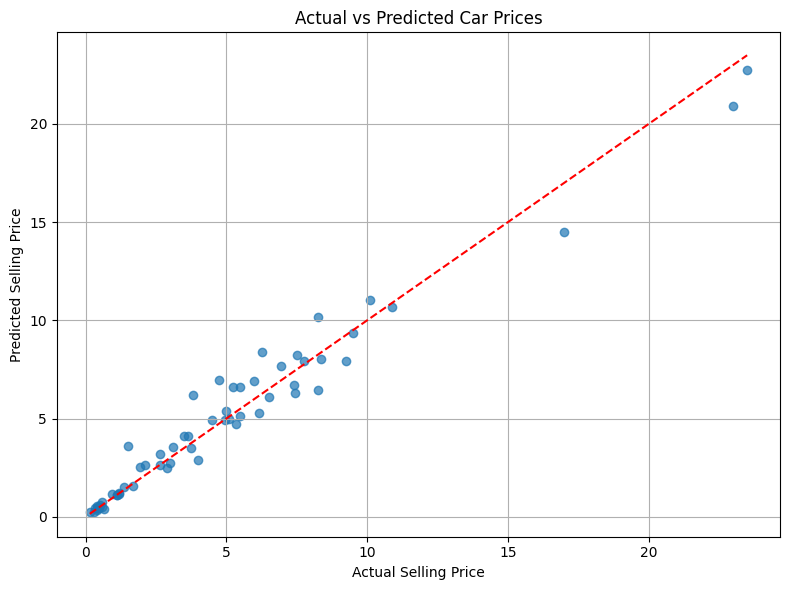

In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title('Actual vs Predicted Car Prices')
plt.xlabel('Actual Selling Price')
plt.ylabel('Predicted Selling Price')
plt.grid(True)
plt.tight_layout()
plt.show()

,Feature,Importance
1,Present_Price,0.8810
2,Driven_kms,0.0342
4,Car_Age,0.0340
0,Year,0.0328
8,Transmission_Manual,0.0091
5,Fuel_Type_Diesel,0.0035
6,Fuel_Type_Petrol,0.0029
7,Selling_type_Individual,0.0021
3,Owner,0.0004


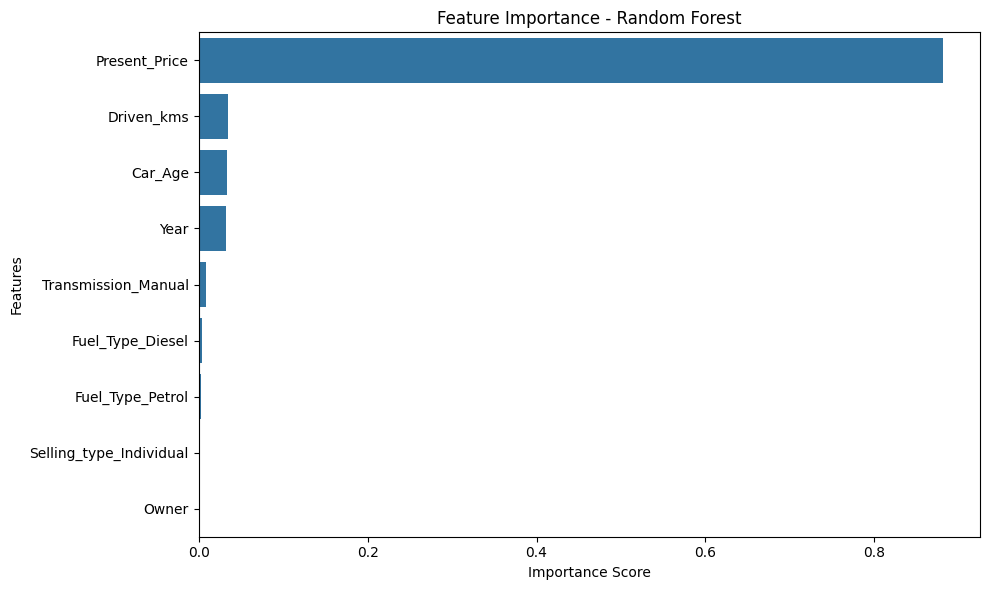

In [18]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.round(4))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [19]:
# Create a sample vehicle
sample_vehicle = pd.DataFrame([{
    'Year': 2018,
    'Present_Price': 8.0,
    'Driven_kms': 25000,
    'Owner': 0,
    'Car_Age': latest_year - 2018,
    'Fuel_Type_Diesel': 0,
    'Fuel_Type_Petrol': 1,
    'Selling_type_Individual': 0,
    'Transmission_Manual': 1
}])

# Predict selling price
predicted_price = best_model.predict(sample_vehicle)

print("Predicted Selling Price:", round(predicted_price[0], 2))

Predicted Selling Price: 6.12


In [20]:
import joblib

joblib.dump(best_model, 'car_price_prediction_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [21]:
loaded_model = joblib.load('car_price_prediction_model.pkl')

test_prediction = loaded_model.predict(sample_vehicle)

print("Loaded Model Prediction:", round(test_prediction[0], 2))

Loaded Model Prediction: 6.12


In [22]:
print("Dataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())
print("Best Model: Random Forest")
print("R2 Score: 0.962")

Dataset Shape: (301, 10)
Duplicate Rows: 2
Missing Values: 0
Best Model: Random Forest
R2 Score: 0.962


In [23]:
import pandas as pd

df = pd.read_csv('/content/car data.csv')

print("Before Cleaning:", df.shape)

df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("After Cleaning:", df.shape)
print("Duplicates:", df.duplicated().sum())

Before Cleaning: (301, 9)
After Cleaning: (299, 9)
Duplicates: 0


In [24]:
# Feature Engineering
latest_year = df['Year'].max()
df['Car_Age'] = latest_year - df['Year']

# Encoding
model_df = df.drop('Car_Name', axis=1)

model_df = pd.get_dummies(
    model_df,
    columns=['Fuel_Type', 'Selling_type', 'Transmission'],
    drop_first=True,
    dtype=int
)

# Separate features and target
X = model_df.drop('Selling_Price', axis=1)
y = model_df['Selling_Price']

print("Dataset Shape:", model_df.shape)
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Dataset Shape: (299, 10)
X Shape: (299, 9)
y Shape: (299,)


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (239, 9)
Testing Data: (60, 9)


In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

print("All models trained successfully!")

All models trained successfully!


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': round(mae, 3),
        'MSE': round(mse, 3),
        'RMSE': round(rmse, 3),
        'R2 Score': round(r2, 3)
    })

results_df = pd.DataFrame(results)
print(results_df)

               Model    MAE     MSE   RMSE  R2 Score
0  Linear Regression  1.473   6.373  2.525     0.753
1      Decision Tree  1.149   4.546  2.132     0.824
2      Random Forest  1.523  13.812  3.716     0.464


In [28]:
best_model = trained_models['Decision Tree']

print("Best Model: Decision Tree")
print("R2 Score: 0.824")
print("Model selected successfully!")

Best Model: Decision Tree
R2 Score: 0.824
Model selected successfully!


In [29]:
predictions = best_model.predict(X_test)

comparison_df = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': predictions
})

comparison_df['Difference'] = (
    comparison_df['Actual Price'] - comparison_df['Predicted Price']
)

print(comparison_df.head(15).round(2))

    Actual Price  Predicted Price  Difference
0           8.99             7.25        1.74
1           8.35             9.50       -1.15
2           0.45             0.45        0.00
3           7.45             5.95        1.50
4           5.25             9.25       -4.00
5           5.25             5.30       -0.05
6           5.85             7.45       -1.60
7           1.15             1.20       -0.05
8           9.25             7.25        2.00
9           0.38             0.15        0.23
10          9.65             9.25        0.40
11          0.16             0.25       -0.09
12          0.25             0.27       -0.02
13          0.48             0.48        0.00
14          4.10             4.75       -0.65


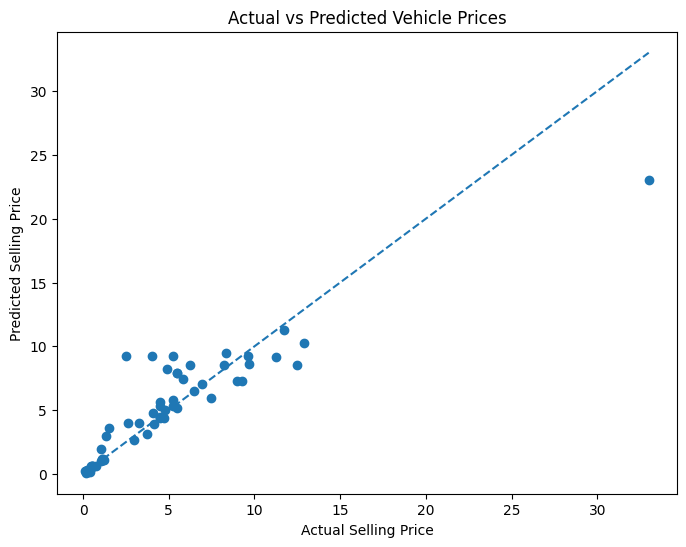

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Vehicle Prices")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.show()

In [31]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                   Feature    Importance
1            Present_Price  9.170016e-01
4                  Car_Age  7.007176e-02
2               Driven_kms  6.212270e-03
0                     Year  5.676322e-03
8      Transmission_Manual  7.837414e-04
5         Fuel_Type_Diesel  1.742102e-04
6         Fuel_Type_Petrol  7.840063e-05
7  Selling_type_Individual  8.537274e-07
3                    Owner  8.224241e-07


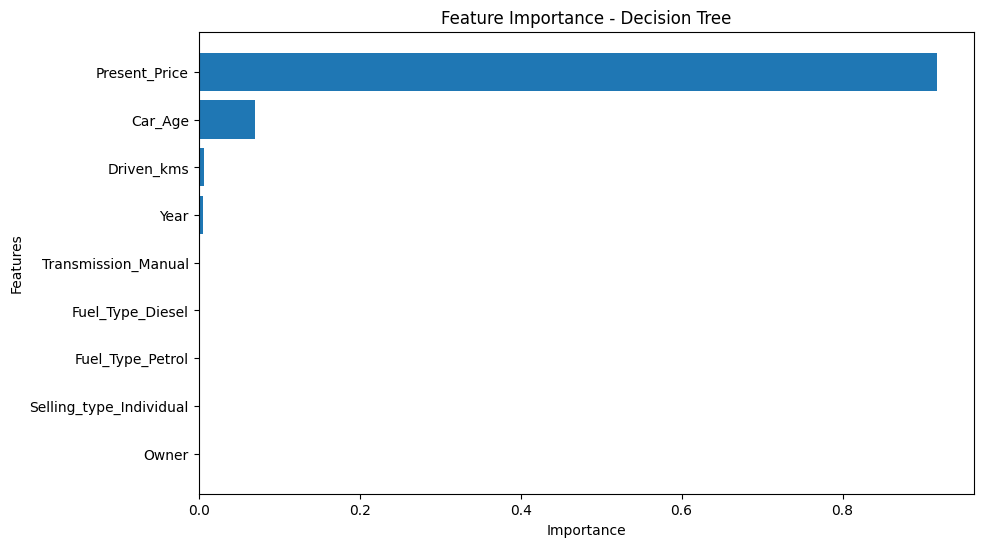

In [32]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Feature Importance - Decision Tree")
plt.gca().invert_yaxis()

plt.show()

In [33]:
import joblib

joblib.dump(best_model, 'car_price_prediction_model.pkl')

print("Decision Tree Model saved successfully!")

# Load model
loaded_model = joblib.load('car_price_prediction_model.pkl')

print("Model loaded successfully!")

Decision Tree Model saved successfully!
Model loaded successfully!


In [34]:
loaded_predictions = loaded_model.predict(X_test)

print("Original Model R2:", round(r2_score(y_test, predictions), 3))
print("Loaded Model R2:", round(r2_score(y_test, loaded_predictions), 3))

Original Model R2: 0.824
Loaded Model R2: 0.824


In [35]:
print("Final Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Best Model: Decision Tree")
print("Final R2 Score:", round(r2_score(y_test, predictions), 3))

Final Dataset Shape: (299, 10)
Missing Values: 0
Duplicate Rows: 0
Best Model: Decision Tree
Final R2 Score: 0.824


Conclusion
This project focused on predicting vehicle selling prices using Machine Learning techniques.

The dataset was cleaned by removing duplicate records and handling categorical features using One-Hot Encoding. Exploratory Data Analysis was performed to understand the relationships between different vehicle attributes and selling prices.

Three Machine Learning models were implemented and evaluated:
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
Among these models, the Decision Tree Regressor performed best with an R² Score of 0.824, MAE of 1.149, and RMSE of 2.132 on the test dataset.

The analysis demonstrated that vehicle pricing can be influenced by factors such as present price, vehicle age, kilometers driven, fuel type, and transmission.

Overall, this project provided practical experience in data cleaning, exploratory data analysis, feature engineering, model training, evaluation, and prediction using Python.